# VFU-StressTest: stress-testing vertical federated unlearning

**Pilot for the proposal *Stress-Testing Vertical Federated Unlearning under Party Heterogeneity, Distribution Shift, and Continued Training*.**
Author: Ashhar Hussain · [github.com/Ashhar-Hussain](https://github.com/Ashhar-Hussain)

This notebook reproduces the core evaluation protocol of **REMISVFU** (Wu et al., AAAI 2026, [doi:10.1609/aaai.v40i32.39911](https://doi.org/10.1609/aaai.v40i32.39911)) at small scale. It then asks whether its forgetting certificate holds when conditions change:

| Block | Question |
|---|---|
| **Reference** | Original backdoored 3-party split-VFL model, retrain-from-scratch without the forgotten party (gold reference), REMISVFU-style representation-misdirection unlearning, and a never-poisoned 3-party model |
| **Axis A: party heterogeneity** | Does forgetting/utility change when the **left, centre, or right** slice is the forgotten party? |
| **Axis B: distribution shift** | Does forgetting hold for **shifted trigger variants**? Does the unlearned model degrade more than retraining under **input noise** on the remaining parties? |
| **Axis C: continued training** | How fast can the backdoor be **relearned** from a small poisoned budget, compared with a model that never learned it? |
| **Audit** | Can **linear probes** recover labels / trigger presence from the forgotten party's representation? |
| **Statistics** | Multi-seed means with **95% CIs**, paired **McNemar** tests vs. retraining with **Holm** correction, and unlearning **time cost** |

### How to run (Google Colab, free)
1. `Runtime → Change runtime type → T4 GPU` (free tier), then `Runtime → Run all`.
2. The mode is chosen automatically: **FULL** on GPU (MNIST + Fashion-MNIST, 5 seeds, 3 positions), **QUICK** on CPU (MNIST, 3 seeds, reduced data).
3. Results are written to `results/summary.md` and `results/raw.json`.

*TPU is not used: these models are tiny, so PyTorch/XLA compilation overhead outweighs any gain. A T4 GPU or the CPU runtime is the right choice.*

**Pilot status:** settings that the REMISVFU paper does not specify (optimizer, learning rate, unlearning epochs) are fixed explicitly below. Numbers from this notebook are preliminary and are not the paper's numbers.

In [1]:
# ---- Setup and configuration -------------------------------------------------
import os, time, json, copy, random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODE = os.environ.get('VFU_MODE', 'FULL' if DEVICE.type == 'cuda' else 'QUICK')   # FULL | QUICK | SMOKE
CFG = {
    'FULL':  dict(datasets=['MNIST', 'FashionMNIST'], seeds=[0, 1, 2, 3, 4], n_train=None,  n_test=None,
                  ep_train=5, ep_unlearn=3, positions=[1, 0, 2]),
    'QUICK': dict(datasets=['MNIST'], seeds=[0, 1, 2], n_train=20000, n_test=5000,
                  ep_train=3, ep_unlearn=2, positions=[1, 0]),
    'SMOKE': dict(datasets=['MNIST', 'FashionMNIST'], seeds=[0, 1], n_train=3000, n_test=1000,
                  ep_train=1, ep_unlearn=1, positions=[1, 0, 2]),
}[MODE]

# REMISVFU protocol constants (Wu et al., AAAI 2026)
K = 3                # passive parties = equal vertical image slices
TARGET = 0           # backdoor target label
POISON_RATE = 0.10   # ~10% of training images poisoned in the forgotten party's slice
TRIG = 2             # 2x2 white trigger, lower-right corner of the forgotten slice
C_ANCHOR = 1.0       # anchor scale c
ALPHA = 1e-3         # retention weight alpha
# Settings not specified in the paper (fixed here, documented in the README)
LR, BS = 1e-3, 256   # Adam learning rate and batch size for training and unlearning
RELEARN_STEPS = [0, 10, 25, 50, 100]   # relearning probe checkpoints (batch 64)
NOISE_SIGMAS = [0.2, 0.4]              # covariate shift on remaining parties' slices
POS_NAME = {0: 'left', 1: 'centre', 2: 'right'}

if DEVICE.type == 'cuda':
    torch.backends.cudnn.benchmark = True
print(f'device={DEVICE} | mode={MODE} | config={CFG}')

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

device=cuda | mode=FULL | config={'datasets': ['MNIST', 'FashionMNIST'], 'seeds': [0, 1, 2, 3, 4], 'n_train': None, 'n_test': None, 'ep_train': 5, 'ep_unlearn': 3, 'positions': [1, 0, 2]}


In [2]:
# ---- Data, vertical partition, trigger -------------------------------------
from torchvision import datasets

def load(name, root='./data'):
    D = getattr(datasets, name)
    tr, te = D(root, train=True, download=True), D(root, train=False, download=True)
    def prep(ds, n):
        x = ds.data.float().div(255.).unsqueeze(1)          # N x 1 x 28 x 28 in [0, 1]
        y = torch.as_tensor(ds.targets).long().clone()
        if n is not None and n < len(y):
            idx = torch.randperm(len(y), generator=torch.Generator().manual_seed(1234))[:n]
            x, y = x[idx], y[idx]
        return x, y
    return prep(tr, CFG['n_train']), prep(te, CFG['n_test'])

W = 28
BOUNDS = [(int(c[0]), int(c[-1]) + 1) for c in np.array_split(np.arange(W), K)]   # [(0,10), (10,19), (19,28)]

def split(x):
    return [x[..., a:b] for a, b in BOUNDS]

def stamp(x, party, variant='exact'):
    # Stamp a trigger into party's slice. 'exact' is the training trigger; the rest are shifted variants (Axis B).
    x = x.clone(); a, b = BOUNDS[party]; H = x.shape[-2]
    r, c, s, v = {
        'exact':  (H - TRIG,     b - TRIG,     TRIG, 1.0),
        'shift1': (H - TRIG - 1, b - TRIG - 1, TRIG, 1.0),
        'shift2': (H - TRIG - 2, b - TRIG - 2, TRIG, 1.0),
        'size3':  (H - 3,        b - 3,        3,    1.0),
        'dim':    (H - TRIG,     b - TRIG,     TRIG, 0.6),
        'corner': (H - TRIG,     a,            TRIG, 1.0),   # lower-left corner of the slice
    }[variant]
    x[..., r:r + s, c:c + s] = v
    return x

def poison(x, y, party, rate, seed):
    g = torch.Generator().manual_seed(seed)
    cand = torch.nonzero(y != TARGET).squeeze(1)
    idx = cand[torch.randperm(len(cand), generator=g)[:int(rate * len(y))]]
    x, y = x.clone(), y.clone()
    x[idx] = stamp(x[idx], party); y[idx] = TARGET
    return x, y

def corrupt_remaining(x, forget_pos, sigma, seed):
    # Gaussian noise on every slice except the forgotten party's (covariate shift, Axis B).
    noise = torch.randn(x.shape, generator=torch.Generator().manual_seed(seed)) * sigma
    a, b = BOUNDS[forget_pos]; noise[..., a:b] = 0
    return (x + noise).clamp(0, 1)

In [3]:
# ---- Split-VFL model (bottom encoders + top model, as in REMISVFU) ----------
class Bottom(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                 nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten())
    def forward(self, x):
        return self.net(x)

class VFL(nn.Module):
    # Passive parties = image slices in `parties`; a label-only active party holds the top model.
    def __init__(self, parties, n_cls=10):
        super().__init__()
        self.parties = list(parties)
        self.bottoms = nn.ModuleList([Bottom() for _ in self.parties])
        with torch.no_grad():
            d = sum(b(torch.zeros(1, 1, 28, BOUNDS[p][1] - BOUNDS[p][0])).shape[1]
                    for b, p in zip(self.bottoms, self.parties))
        self.top = nn.Sequential(nn.Linear(d, 128), nn.ReLU(), nn.Linear(128, n_cls))
    def reps(self, x):
        xs = split(x)
        return [b(xs[p]) for b, p in zip(self.bottoms, self.parties)]
    def forward(self, x, return_reps=False):
        h = self.reps(x); z = self.top(torch.cat(h, 1))
        return (z, h) if return_reps else z

def batches(n, bs, gen):
    perm = torch.randperm(n, generator=gen)
    for i in range(0, n, bs):
        yield perm[i:i + bs].to(DEVICE)

def train(model, x, y, epochs, seed):
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    g = torch.Generator().manual_seed(seed); model.train()
    for _ in range(epochs):
        for idx in batches(len(y), BS, g):
            loss = F.cross_entropy(model(x[idx]), y[idx])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    return model

@torch.no_grad()
def predict(model, x, bs=2048):
    model.eval()
    return torch.cat([model(x[i:i + bs].to(DEVICE)).argmax(1).cpu() for i in range(0, len(x), bs)])

def clean_acc(model, xt, yt):
    return (predict(model, xt) == yt).float().mean().item()

def asr(model, xt, party, variant='exact'):
    # Backdoor success as in REMISVFU: share of ALL triggered test images predicted as TARGET.
    # A model without the backdoor sits near the class prior (about 10% for these datasets).
    return (predict(model, stamp(xt, party, variant)) == TARGET).float().mean().item()

In [4]:
# ---- REMISVFU-style unlearning: representation misdirection + gradient projection ----
def remisvfu(model, x, y, forget_pos, epochs, seed, c=C_ANCHOR, alpha=ALPHA):
    # The forgetting party pushes its encoder output to a fixed random anchor c*u on the unit sphere (L_f).
    # The server keeps the task loss (L_r); if <g_f, g_r> < 0, g_r is projected orthogonal to g_f.
    # Update: g_f + alpha * g_r' (Eq. 18-19 of REMISVFU).
    j = model.parties.index(forget_pos)
    g = torch.Generator().manual_seed(seed + 999)
    with torch.no_grad():
        d_h = model.reps(x[:1])[j].shape[1]
    u = torch.randn(d_h, generator=g); u = (u / u.norm()).to(DEVICE)       # drawn once, kept fixed
    params = list(model.parameters())
    pf = list(model.bottoms[j].parameters()); pf_ids = {id(p) for p in pf}
    opt = torch.optim.Adam(params, lr=LR); model.train()
    for _ in range(epochs):
        for idx in batches(len(y), BS, g):
            z, h = model(x[idx], return_reps=True)
            Lf = ((h[j] - c * u) ** 2).sum(1).mean()
            Lr = F.cross_entropy(z, y[idx])
            gf = torch.autograd.grad(Lf, pf, retain_graph=True)
            gr = torch.autograd.grad(Lr, params)
            gr_f = [gr[i] for i, p in enumerate(params) if id(p) in pf_ids]
            dot = sum((a * b).sum() for a, b in zip(gf, gr_f))
            coef = dot / (sum((a * a).sum() for a in gf) + 1e-12) if dot < 0 else 0.0
            gfi = iter(gf)
            for p, g_r in zip(params, gr):
                if id(p) in pf_ids:
                    g_f = next(gfi); p.grad = g_f + alpha * (g_r - coef * g_f)
                else:
                    p.grad = alpha * g_r
            opt.step()
    return model

In [5]:
# ---- Stress tests and audits -----------------------------------------------
VARIANTS = ['exact', 'shift1', 'shift2', 'size3', 'dim', 'corner']

def relearn_curve(model, x_pool, y_pool, xt, pos, seed):
    # Axis C: fine-tune ALL parameters on a small poisoned budget; record backdoor success over steps.
    m = copy.deepcopy(model); opt = torch.optim.Adam(m.parameters(), lr=LR)
    g = torch.Generator().manual_seed(seed + 7); curve, step = {0: asr(m, xt, pos)}, 0
    while step < max(RELEARN_STEPS):
        for idx in batches(len(y_pool), 64, g):
            m.train(); loss = F.cross_entropy(m(x_pool[idx]), y_pool[idx])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); step += 1
            if step in RELEARN_STEPS:
                curve[step] = asr(m, xt, pos)
            if step >= max(RELEARN_STEPS):
                break
    return curve

@torch.no_grad()
def forgotten_reps(model, x, pos, bs=1024):
    model.eval(); j = model.parties.index(pos)
    return torch.cat([model.reps(x[i:i + bs].to(DEVICE))[j].cpu() for i in range(0, len(x), bs)]).numpy()

def probe_acc(feats, labels, seed):
    # Linear-probe recovery: 50/50 split, standardised logistic regression.
    n = len(labels); idx = np.random.RandomState(seed).permutation(n); tr, te = idx[:n // 2], idx[n // 2:]
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    clf.fit(feats[tr], labels[tr]); return float(clf.score(feats[te], labels[te]))

def probes(model, xt, yt, pos, seed, n=2000):
    x = xt[:n]; y = yt[:n].numpy()
    f_clean = forgotten_reps(model, x, pos); f_trig = forgotten_reps(model, stamp(x, pos), pos)
    label_probe = probe_acc(f_clean, y, seed)
    trig_probe = probe_acc(np.concatenate([f_clean, f_trig]), np.r_[np.zeros(len(y)), np.ones(len(y))], seed)
    return label_probe, trig_probe

def mcnemar_p(pred_a, pred_b, yt):
    # Exact two-sided McNemar test on per-sample correctness.
    ca, cb = (pred_a == yt).numpy(), (pred_b == yt).numpy()
    b, c = int((ca & ~cb).sum()), int((~ca & cb).sum())
    return 1.0 if b + c == 0 else float(stats.binomtest(min(b, c), b + c, 0.5).pvalue), b, c

def holm(pvals):
    m = len(pvals); order = np.argsort(pvals); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, min(1.0, (m - rank) * pvals[i])); adj[i] = run
    return adj

def ci95(v):
    v = np.asarray(v, float); n = len(v); m = v.mean()
    if n < 2:
        return m, float('nan')
    return m, stats.t.ppf(0.975, n - 1) * v.std(ddof=1) / np.sqrt(n)

In [6]:
# ---- Main experiment loop ---------------------------------------------------
RESULTS = []
t_start = time.time()
for ds in CFG['datasets']:
    (xtr, ytr), (xte, yte) = load(ds)
    xtr_d, ytr_d = xtr.to(DEVICE), ytr.to(DEVICE)
    for seed in CFG['seeds']:
        set_seed(seed)
        clean3 = train(VFL(range(K)).to(DEVICE), xtr_d, ytr_d, CFG['ep_train'], seed)    # never poisoned
        for pos in CFG['positions']:
            xp, yp = poison(xtr, ytr, pos, POISON_RATE, seed)
            xp_d, yp_d = xp.to(DEVICE), yp.to(DEVICE)
            set_seed(seed); t0 = time.time()
            orig = train(VFL(range(K)).to(DEVICE), xp_d, yp_d, CFG['ep_train'], seed); t_orig = time.time() - t0
            set_seed(seed); t0 = time.time()
            retr = train(VFL([p for p in range(K) if p != pos]).to(DEVICE), xp_d, yp_d, CFG['ep_train'], seed)
            t_retr = time.time() - t0
            set_seed(seed); t0 = time.time()
            unl = remisvfu(copy.deepcopy(orig), xp_d, yp_d, pos, CFG['ep_unlearn'], seed); t_unl = time.time() - t0

            p_retr, p_unl = predict(retr, xte), predict(unl, xte)
            p_val, n_b, n_c = mcnemar_p(p_unl, p_retr, yte)
            row = dict(dataset=ds, seed=seed, position=POS_NAME[pos],
                       acc_orig=clean_acc(orig, xte, yte), acc_retrain=float((p_retr == yte).float().mean()),
                       acc_unlearn=float((p_unl == yte).float().mean()), acc_clean3=clean_acc(clean3, xte, yte),
                       asr_orig=asr(orig, xte, pos), asr_retrain=asr(retr, xte, pos),
                       asr_unlearn=asr(unl, xte, pos), asr_natural=asr(clean3, xte, pos),
                       mcnemar_p=p_val, unl_only_correct=n_b, retr_only_correct=n_c,
                       time_unlearn_pct_of_retrain=100 * t_unl / max(t_retr, 1e-9))
            for v in VARIANTS[1:]:                                                      # Axis B: trigger shift
                row[f'asr_orig_{v}'] = asr(orig, xte, pos, v); row[f'asr_unlearn_{v}'] = asr(unl, xte, pos, v)
            for s in NOISE_SIGMAS:                                                      # Axis B: covariate shift
                xs = corrupt_remaining(xte, pos, s, seed)
                row[f'acc_retrain_noise{s}'] = clean_acc(retr, xs, yte); row[f'acc_unlearn_noise{s}'] = clean_acc(unl, xs, yte)
            pool_x, pool_y = poison(xtr[:1024], ytr[:1024], pos, POISON_RATE, seed + 1)    # Axis C budget
            pool_x, pool_y = pool_x.to(DEVICE), pool_y.to(DEVICE)
            for name, m in [('unlearn', unl), ('clean3', clean3)]:
                for st, val in relearn_curve(m, pool_x, pool_y, xte, pos, seed).items():
                    row[f'relearn_{name}_{st}'] = val
            for name, m in [('orig', orig), ('unlearn', unl)]:                         # representation audit
                lp, tp = probes(m, xte, yte, pos, seed); row[f'probe_label_{name}'] = lp; row[f'probe_trigger_{name}'] = tp
            RESULTS.append(row)
            print(f"[{time.time() - t_start:6.0f}s] {ds:12s} seed={seed} forget={POS_NAME[pos]:6s} "
                  f"acc orig/retr/unl={row['acc_orig']:.3f}/{row['acc_retrain']:.3f}/{row['acc_unlearn']:.3f} "
                  f"ASR orig/unl/natural={row['asr_orig']:.3f}/{row['asr_unlearn']:.3f}/{row['asr_natural']:.3f}")
print(f'Done in {(time.time() - t_start) / 60:.1f} min')

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.09MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 136kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.29MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.56MB/s]


[    46s] MNIST        seed=0 forget=centre acc orig/retr/unl=0.985/0.913/0.904 ASR orig/unl/natural=0.994/0.432/0.097
[    73s] MNIST        seed=0 forget=left   acc orig/retr/unl=0.985/0.977/0.970 ASR orig/unl/natural=1.000/0.253/0.097
[   100s] MNIST        seed=0 forget=right  acc orig/retr/unl=0.985/0.979/0.984 ASR orig/unl/natural=0.999/0.934/0.098
[   131s] MNIST        seed=1 forget=centre acc orig/retr/unl=0.986/0.901/0.907 ASR orig/unl/natural=0.999/0.133/0.100
[   160s] MNIST        seed=1 forget=left   acc orig/retr/unl=0.985/0.968/0.965 ASR orig/unl/natural=1.000/0.344/0.100
[   189s] MNIST        seed=1 forget=right  acc orig/retr/unl=0.986/0.979/0.983 ASR orig/unl/natural=1.000/0.747/0.100
[   220s] MNIST        seed=2 forget=centre acc orig/retr/unl=0.982/0.905/0.908 ASR orig/unl/natural=0.998/0.445/0.098
[   246s] MNIST        seed=2 forget=left   acc orig/retr/unl=0.984/0.977/0.973 ASR orig/unl/natural=1.000/0.140/0.098
[   272s] MNIST        seed=2 forget=right  acc 

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 172kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.08MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 27.6MB/s]


[   490s] FashionMNIST seed=0 forget=centre acc orig/retr/unl=0.894/0.860/0.865 ASR orig/unl/natural=0.991/0.240/0.117
[   517s] FashionMNIST seed=0 forget=left   acc orig/retr/unl=0.896/0.890/0.895 ASR orig/unl/natural=0.987/0.125/0.122
[   543s] FashionMNIST seed=0 forget=right  acc orig/retr/unl=0.897/0.886/0.890 ASR orig/unl/natural=1.000/0.250/0.116
[   577s] FashionMNIST seed=1 forget=centre acc orig/retr/unl=0.890/0.862/0.864 ASR orig/unl/natural=0.982/0.403/0.090
[   605s] FashionMNIST seed=1 forget=left   acc orig/retr/unl=0.890/0.886/0.891 ASR orig/unl/natural=0.995/0.138/0.098
[   631s] FashionMNIST seed=1 forget=right  acc orig/retr/unl=0.894/0.889/0.889 ASR orig/unl/natural=1.000/0.424/0.094
[   663s] FashionMNIST seed=2 forget=centre acc orig/retr/unl=0.883/0.844/0.862 ASR orig/unl/natural=0.998/0.216/0.110
[   691s] FashionMNIST seed=2 forget=left   acc orig/retr/unl=0.881/0.879/0.889 ASR orig/unl/natural=0.996/0.111/0.116
[   719s] FashionMNIST seed=2 forget=right  acc 

In [7]:
# ---- Summary: means with 95% CIs, Holm-corrected McNemar, write results/ ---
os.makedirs('results', exist_ok=True)
json.dump(dict(mode=MODE, config=CFG, device=str(DEVICE), rows=RESULTS), open('results/raw.json', 'w'), indent=1)
adj = holm(np.array([r['mcnemar_p'] for r in RESULTS]))
for r, a in zip(RESULTS, adj):
    r['mcnemar_p_holm'] = float(a)

def fmt(key, rows, pct=True):
    m, h = ci95([r[key] for r in rows]); k = 100 if pct else 1
    return f'{k * m:.1f}' if np.isnan(h) else f'{k * m:.1f} ± {k * h:.1f}'

groups = {}
for r in RESULTS:
    groups.setdefault((r['dataset'], r['position']), []).append(r)

L = [f'# VFU-StressTest pilot results ({MODE} mode, device: {DEVICE})', '',
     f'Seeds: {CFG["seeds"]}. Values are mean ± 95% CI half-width across seeds (t-interval), in %.', '',
     '## Reference comparison and Axis A (forgotten-party position)', '',
     '| Dataset | Forgotten | Acc orig | Acc retrain | Acc unlearn | ASR orig | ASR unlearn | ASR natural | Unlearn time (% of retrain) | McNemar significant (Holm, p<0.05) |',
     '|---|---|---|---|---|---|---|---|---|---|']
for (ds, pos), rows in groups.items():
    sig = sum(r['mcnemar_p_holm'] < 0.05 for r in rows)
    L.append(f"| {ds} | {pos} | {fmt('acc_orig', rows)} | {fmt('acc_retrain', rows)} | {fmt('acc_unlearn', rows)} | "
             f"{fmt('asr_orig', rows)} | {fmt('asr_unlearn', rows)} | {fmt('asr_natural', rows)} | "
             f"{fmt('time_unlearn_pct_of_retrain', rows, pct=False)} | {sig}/{len(rows)} seeds |")
L += ['', '## Axis B: backdoor success under shifted triggers (original → unlearned)', '',
      '| Dataset | Forgotten | ' + ' | '.join(VARIANTS[1:]) + ' |', '|---|---|' + '---|' * (len(VARIANTS) - 1)]
for (ds, pos), rows in groups.items():
    L.append(f'| {ds} | {pos} | ' + ' | '.join(f"{fmt(f'asr_orig_{v}', rows)} → {fmt(f'asr_unlearn_{v}', rows)}"
                                             for v in VARIANTS[1:]) + ' |')
L += ['', '## Axis B: clean accuracy under noise on the remaining parties (retrain vs. unlearned)', '',
      '| Dataset | Forgotten | ' + ' | '.join(f'σ={s}' for s in NOISE_SIGMAS) + ' |', '|---|---|' + '---|' * len(NOISE_SIGMAS)]
for (ds, pos), rows in groups.items():
    L.append(f'| {ds} | {pos} | ' + ' | '.join(f"{fmt(f'acc_retrain_noise{s}', rows)} vs {fmt(f'acc_unlearn_noise{s}', rows)}"
                                             for s in NOISE_SIGMAS) + ' |')
L += ['', '## Axis C: relearning probe (backdoor success after k fine-tuning steps; unlearned vs. never-poisoned)', '',
      '| Dataset | Forgotten | ' + ' | '.join(f'k={k}' for k in RELEARN_STEPS) + ' |', '|---|---|' + '---|' * len(RELEARN_STEPS)]
for (ds, pos), rows in groups.items():
    L.append(f'| {ds} | {pos} | ' + ' | '.join(f"{fmt(f'relearn_unlearn_{k}', rows)} vs {fmt(f'relearn_clean3_{k}', rows)}"
                                             for k in RELEARN_STEPS) + ' |')
L += ['', '## Representation audit: linear-probe accuracy on the forgotten party\'s representation (original → unlearned)', '',
      '| Dataset | Forgotten | Label probe | Trigger probe (chance = 50) |', '|---|---|---|---|']
for (ds, pos), rows in groups.items():
    L.append(f"| {ds} | {pos} | {fmt('probe_label_orig', rows)} → {fmt('probe_label_unlearn', rows)} | "
             f"{fmt('probe_trigger_orig', rows)} → {fmt('probe_trigger_unlearn', rows)} |")
L += ['', 'Notes: ASR follows the REMISVFU convention (share of all triggered test images predicted as the target label), so a '
      'backdoor-free model sits near the class prior (see "ASR natural"). Retraining removes the forgotten slice, so its '
      'representation probes are at chance by construction. Pilot settings not given in the paper: Adam (lr 1e-3), batch 256.']
open('results/summary.md', 'w').write('\n'.join(L))
print('\n'.join(L))

# VFU-StressTest pilot results (FULL mode, device: cuda)

Seeds: [0, 1, 2, 3, 4]. Values are mean ± 95% CI half-width across seeds (t-interval), in %.

## Reference comparison and Axis A (forgotten-party position)

| Dataset | Forgotten | Acc orig | Acc retrain | Acc unlearn | ASR orig | ASR unlearn | ASR natural | Unlearn time (% of retrain) | McNemar significant (Holm, p<0.05) |
|---|---|---|---|---|---|---|---|---|---|
| MNIST | centre | 98.5 ± 0.2 | 90.6 ± 0.6 | 90.2 ± 1.0 | 99.8 ± 0.3 | 37.9 ± 17.7 | 9.9 ± 0.1 | 107.0 ± 3.7 | 3/5 seeds |
| MNIST | left | 98.5 ± 0.1 | 97.4 ± 0.5 | 96.6 ± 1.4 | 100.0 ± 0.0 | 26.2 ± 16.7 | 9.9 ± 0.2 | 122.6 ± 5.9 | 2/5 seeds |
| MNIST | right | 98.5 ± 0.2 | 97.7 ± 0.2 | 98.1 ± 0.5 | 100.0 ± 0.0 | 88.8 ± 10.2 | 9.9 ± 0.1 | 107.2 ± 3.3 | 4/5 seeds |
| FashionMNIST | centre | 89.2 ± 0.7 | 85.5 ± 0.9 | 86.4 ± 0.4 | 99.2 ± 0.8 | 25.7 ± 12.9 | 10.7 ± 1.5 | 107.3 ± 4.3 | 2/5 seeds |
| FashionMNIST | left | 89.2 ± 0.9 | 88.4 ± 0.6 | 89.3 ± 0.8 | 99.4 ± 0.6 |

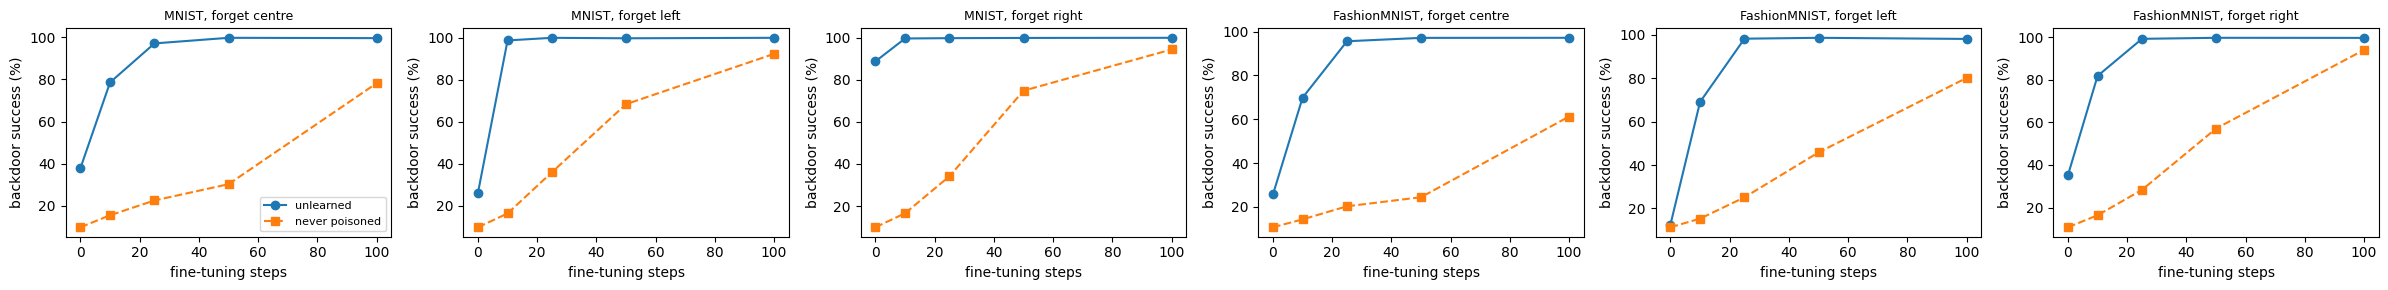

In [8]:
# ---- Optional figure: relearning curves ------------------------------------
try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, len(groups), figsize=(4 * len(groups), 3), squeeze=False)
    for ax, ((ds, pos), rows) in zip(axes[0], groups.items()):
        for name, style in [('unlearn', '-o'), ('clean3', '--s')]:
            m = [100 * np.mean([r[f'relearn_{name}_{k}'] for r in rows]) for k in RELEARN_STEPS]
            ax.plot(RELEARN_STEPS, m, style, label='unlearned' if name == 'unlearn' else 'never poisoned')
        ax.set_title(f'{ds}, forget {pos}', fontsize=9); ax.set_xlabel('fine-tuning steps'); ax.set_ylabel('backdoor success (%)')
    axes[0][0].legend(fontsize=8); plt.tight_layout(); plt.savefig('results/relearning.png', dpi=150); plt.show()
except ImportError:
    print('matplotlib not available; skipping figure')